# Notebook to create Figure S1

In [16]:
cran_packages <- c("tidyverse", "glue", "RColorBrewer")

for (pkg in cran_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  } else {
    message(glue::glue("Already installed package: {pkg}"))
  }
  library(pkg, character.only = TRUE)
}

Already installed package: tidyverse

Already installed package: glue

Already installed package: RColorBrewer



In [22]:
getwd()

[1] "/home/jfrancis/Documents/dna_representation_article/plots"

In [17]:
path <- glue("../Data/ANI")

In [18]:
models <- c("dnaberts", "dnabert2", "hyenadna", "tnf", "dna2vec")

df_all <- map_dfr(models, function(model) {
  read_csv(glue("{path}/ani_vs_emb_{model}.csv"), show_col_types = FALSE) %>%
    mutate(model = model)
}) %>%
  mutate(model = factor(model, levels = models))

In [19]:
model_labels <- c(
  dnaberts  = "DNABERT-S",
  dnabert2  = "DNABERT-2",
  hyenadna  = "HyenaDNA",
  tnf  = "TNF",
  dna2vec   = "dna2vec"
)

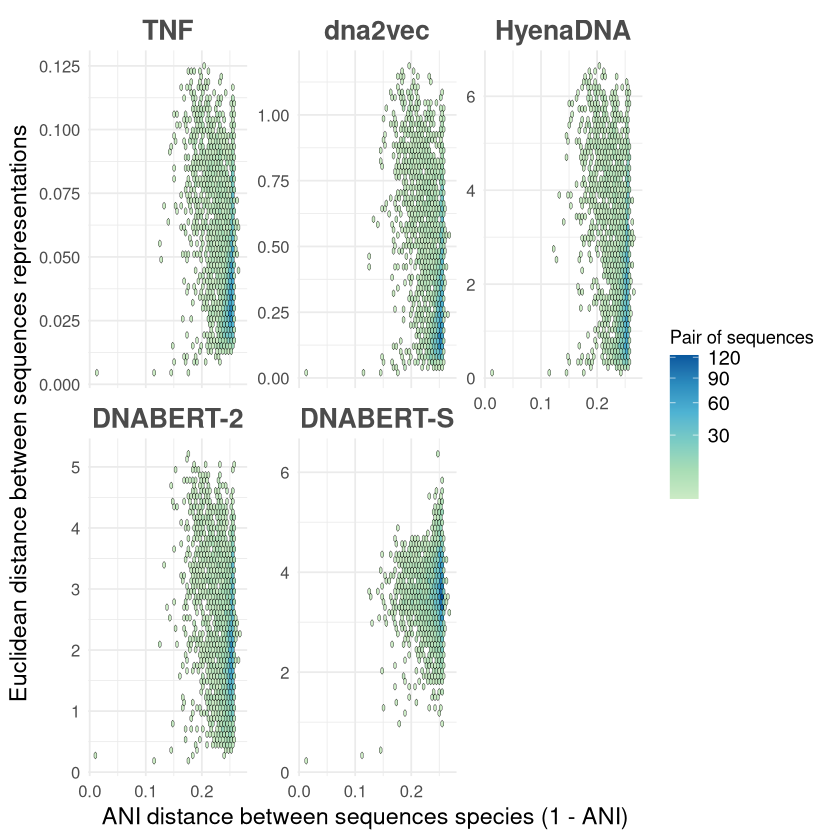

In [20]:
df_all$model <- factor(df_all$model, levels = c("tnf", "dna2vec", "hyenadna", "dnabert2", "dnaberts"))

p <- ggplot(df_all, aes(x = ani, y = emb)) +
  geom_hex(bins = 50, color = "black", linewidth = 0.1) +
  scale_fill_gradientn(
    colors = c("#CCEBC5", "#A8DDB5", "#7BCCC4", "#4EB3D3", "#2B8CBE", "#08589E"),
    trans = "sqrt"
  ) +
  labs(
    x = "ANI distance between sequences species (1 - ANI)",
    y = "Euclidean distance between sequences representations",
    fill = "Pair of sequences"
  ) +
  facet_wrap(~ model, nrow = 2, scales = "free_y",
             labeller = labeller(model = model_labels)) +
  theme_minimal() +
  theme(legend.position = "right", 
        legend.text = element_text(size = 12),
        strip.text = element_text(size = 16, face = "bold", colour = "#4b4b4b"),
        axis.text=element_text(size=10),
        axis.title=element_text(size=14))

p

In [21]:
ggsave(glue("../Results/Plots/ani_vs_representation_figure_S1.png"), p, 
       width = 8, height = 6, dpi = 500)